# Han et al. (2025): Figures 1–7 with lenscape

Han et al. (2025, A&A; [arXiv:2505.22951](https://arxiv.org/abs/2505.22951)) report two planets discovered by
microlensing, **MOA-2022-BLG-091Lb** (four degenerate solutions) and **KMT-2024-BLG-1209Lb** (inner/outer
degeneracy). This notebook redraws Figures 1–7 of the paper with lenscape: light curves, Δχ² maps, model curves and
lens configurations. (Figures 8–10, colour–magnitude diagrams and Bayesian posteriors, need features that
lenscape does not have yet.)

**Data.** The paper's photometry is not public. Its light-curve figures are vector graphics, which store every
plotted point with its error bar; `han2025.py` reads them from the paper's arXiv source (downloaded below) and adds
the public KMTNet baseline outside the plotted window. Nothing derived from the paper is stored in this repository.

**Runtime.** By default the notebook uses lenscape solutions and maps stored in `notebooks/data/` (computed with
exactly these data) and runs in a few minutes. Set `REFIT = True` to refit the solutions (about 5 minutes) and
`RECOMPUTE_MAPS = True` to recompute the maps: about 1.5 hours per map on 12 threads at the paper's resolution
(`step = 1`); `step = 2` uses every other lattice point (4× faster, coarser).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import lenscape
from lenscape import config, figures
import json
import han2025 as H

REFIT = False
RECOMPUTE_MAPS = False
step = 1

backend = lenscape.make_backend(config.REFINE_BACKEND)
stored = json.load(open("data/han2025_solutions.json"))

## Rebuilding the data

In [2]:
src = lenscape.datasets.arxiv_source("2505.22951")            # the paper's LaTeX source with its figures
moa_plotted = H.moa091_plotted(src)                            # Fig. 1: KMTNet + MOA points
kb_plotted = H.kb1209_plotted(src)                             # Fig. 5: KMTNet + OGLE + LCO points
print(moa_plotted, kb_plotted, sep="\n")

Data(716 points, t 9630.86 .. 9706.12, sets {'KMTA22': 61, 'KMTC22': 305, 'KMTS22': 105, 'MOA22': 245})
Data(580 points, t 444.51 .. 537.37, sets {'KMTA': 57, 'KMTC': 118, 'KMTS': 93, 'OGLE': 29, 'LCOA': 85, 'LCOC': 198})


The maps use the plotted points plus the public KMTNet baseline outside the plotted window (it constrains the
blending), mapped onto the paper's flux scale; the added points are normalised separately.

In [3]:
moa_ext, notes = H.extend_baseline(moa_plotted, lenscape.datasets.kmtnet("KMT-2022-BLG-0114"),
                                   stored["MOA-2022-BLG-091"]["baseline_reference"], backend)
print("\n".join(notes))
kb_ext, notes = H.extend_baseline(kb_plotted, lenscape.datasets.kmtnet("KMT-2024-BLG-1209", t_offset=2460000.0),
                                  stored["KMT-2024-BLG-1209"]["baseline_reference"], backend,
                                  match={"KMTA": "KMTA12", "KMTC": "KMTC12", "KMTS": "KMTS12"})
print("\n".join(notes))
print(moa_ext, kb_ext, sep="\n")

KMTA22: 40 shared epochs, added 375 public points (clipped 4), their error factor 2.17
KMTC22: 199 shared epochs, added 823 public points (clipped 3), their error factor 1.56
KMTS22: 66 shared epochs, added 617 public points (clipped 4), their error factor 1.57
KMTA: 20 shared epochs, added 137 public points (clipped 0), their error factor 2.09
KMTC: 43 shared epochs, added 211 public points (clipped 0), their error factor 1.54
KMTS: 36 shared epochs, added 142 public points (clipped 0), their error factor 1.68
Data(2531 points, t 9630.85 .. 9874.29, sets {'KMTA22': 436, 'KMTC22': 1128, 'KMTS22': 722, 'MOA22': 245})
Data(1070 points, t 346.87 .. 600.53, sets {'KMTA': 194, 'KMTC': 329, 'KMTS': 235, 'OGLE': 29, 'LCOA': 85, 'LCOC': 198})


## Solutions

Started from the paper's Tables 2 and 3 (with lenscape's sign convention for u0), fitted to the plotted data.

In [4]:
paper_moa = {"A": (9657.729, 0.02565, 34.68, 1.0029, 4.55e-3, 4.632, -3.0),
             "B": (9657.785, 0.02614, 34.51, 1.0033, 4.36e-3, 4.354, -3.0),
             "C": (9657.699, 0.02642, 34.53, 1.0132, 3.38e-3, 4.811, -3.0),
             "D": (9657.706, 0.02590, 34.54, 1.0195, 4.10e-3, 4.745, -3.0)}
paper_kb = {"Inner": (491.126, 0.0257, 70.11, 1.0599, 3.33e-3, 4.5957, np.log10(0.75e-3)),
            "Outer": (491.141, 0.0249, 73.13, 0.9724, 2.90e-3, 4.5294, np.log10(0.73e-3))}
vec = lambda t0, u0, tE, s, q, al, lr: np.array([t0, -u0, tE, np.log10(s), np.log10(q), al, lr])

if REFIT:
    moa = {k: lenscape.fit_full(moa_plotted, vec(*v))[1] for k, v in paper_moa.items()}
    kb = {k: lenscape.fit_full(kb_plotted, vec(*v))[1] for k, v in paper_kb.items()}
else:
    moa = {k: np.array(v) for k, v in stored["MOA-2022-BLG-091"]["plotted"].items()}
    kb = {k: np.array(v) for k, v in stored["KMT-2024-BLG-1209"]["plotted"].items()}

chi = {k: lenscape.model.chi2(backend, p, moa_plotted) for k, p in moa.items()}
print("MOA-2022-BLG-091 (paper: Sol B best; A +1.1, D +5.0, C +6.7)")
for k, p in moa.items():
    print(f"  Sol {k}: dchi2 {chi[k] - min(chi.values()):5.1f}   s {10 ** p[3]:.4f}  q {10 ** p[4] * 1e3:.2f}e-3  alpha {p[5]:.3f}")
chi = {k: lenscape.model.chi2(backend, p, kb_plotted) for k, p in kb.items()}
print("KMT-2024-BLG-1209 (paper: outer better by 2.0)")
for k, p in kb.items():
    print(f"  {k}: dchi2 {chi[k] - min(chi.values()):5.1f}   s {10 ** p[3]:.4f}  q {10 ** p[4] * 1e3:.2f}e-3  "
          f"tE {p[2]:.1f}  rho {10 ** p[6] * 1e3:.2f}e-3")

MOA-2022-BLG-091 (paper: Sol B best; A +1.1, D +5.0, C +6.7)
  Sol A: dchi2   1.1   s 1.0023  q 4.27e-3  alpha 4.621
  Sol B: dchi2   0.0   s 1.0047  q 4.00e-3  alpha 4.413
  Sol C: dchi2   7.4   s 1.0130  q 3.36e-3  alpha 4.818
  Sol D: dchi2   5.4   s 1.0187  q 3.90e-3  alpha 4.749
KMT-2024-BLG-1209 (paper: outer better by 2.0)
  Inner: dchi2   0.8   s 1.0608  q 3.28e-3  tE 72.5  rho 0.71e-3
  Outer: dchi2   0.0   s 0.9714  q 2.86e-3  tE 75.2  rho 0.70e-3


## Figure 1 — light curve of MOA-2022-BLG-091

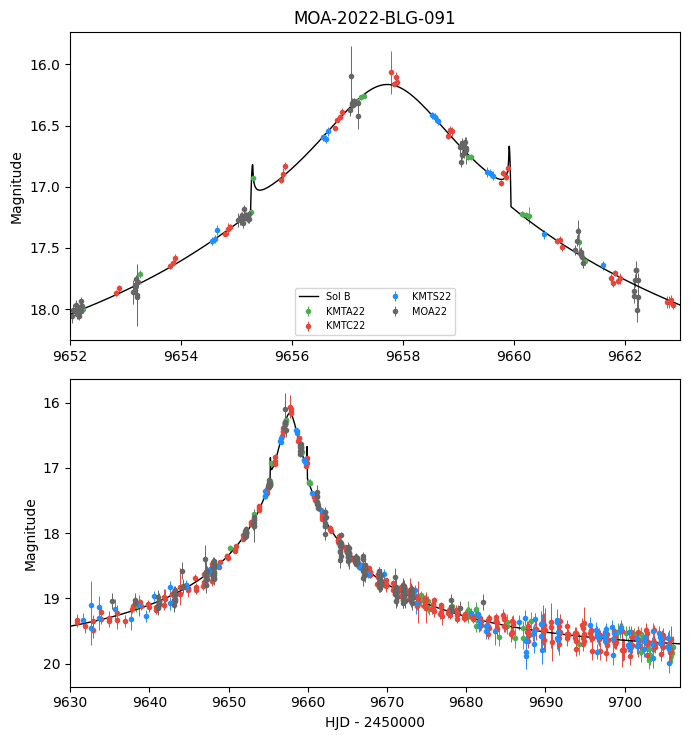

In [5]:
H.plot_two_panels(backend, [("Sol B", "-", moa["B"])], moa_plotted, zoom=(9652, 9663), overall=(9630, 9707),
                  ref=moa_plotted.names.index("KMTC22"), title="MOA-2022-BLG-091");

## Figure 2 — Δχ² maps of MOA-2022-BLG-091

Left pair: (log s, log q); right pair: trajectory angle α of the best fit at every lattice point. The paper's maps
are redrawn from its vector graphics. The paper's lattice has 50 × 49 points.

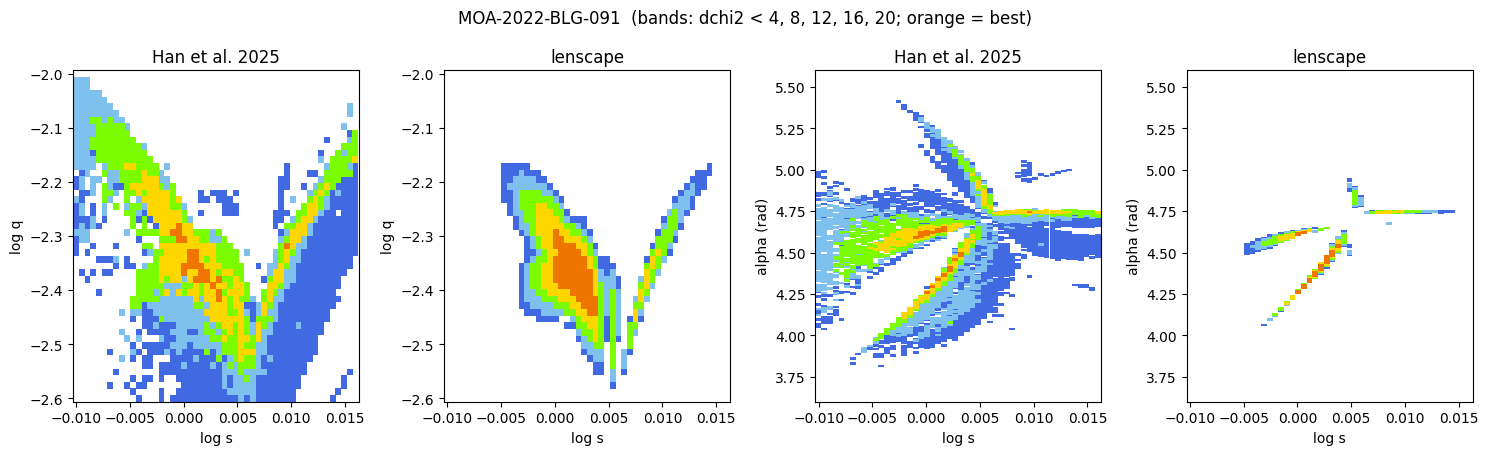

In [6]:
dls, dlq = 0.0005302923409363749, 0.012238426224489748      # the paper's lattice, measured from its figure
if RECOMPUTE_MAPS:
    logs = (-0.010006002352941175 + dls * np.arange(50))[::step]
    logq = (-2.59991008653061 + dlq * np.arange(49))[::step]
    r = lenscape.lattice(moa_ext, logs, logq, best=stored["MOA-2022-BLG-091"]["extended_best"])
    best_u0 = r["pars"][np.unravel_index(np.nanargmin(r["chi2"]), r["chi2"].shape)][1]
    moa_map = dict(r, alpha=np.mod(r["pars"][..., 3] + np.where(np.sign(r["pars"][..., 1]) != np.sign(best_u0), np.pi, 0), 2 * np.pi))
else:
    moa_map = dict(np.load("data/han2025_moa091_lattice.npz"))
left = H.paper_map(src, "f2.eps", (255, 1131, 292, 1605), lenscape.eps.calibrate(592, 0, 918.81, 0.01),
                   lenscape.eps.calibrate(313, -2.6, 2466.5, -1.6))
right = H.paper_map(src, "f2.eps", (1349, 2225, 292, 1605), lenscape.eps.calibrate(1686, 0, 2012.81, 0.01),
                    lenscape.eps.calibrate(554, 4, 1210, 5))
H.compare_maps(left, right, moa_map, (dls * step, dlq * step), 0.016, (-0.0103, 0.0163), (-2.606, -1.994), (3.6, 5.6),
               "MOA-2022-BLG-091");

**Finer cells.** `lenscape.refine` (two levels, down to a quarter of a lattice cell along the band edges) sharpens
the contours. The stored result took 2.6 hours on 19 threads; with `RECOMPUTE_MAPS = True` it is recomputed with
`levels` (each level costs about twice the previous one).

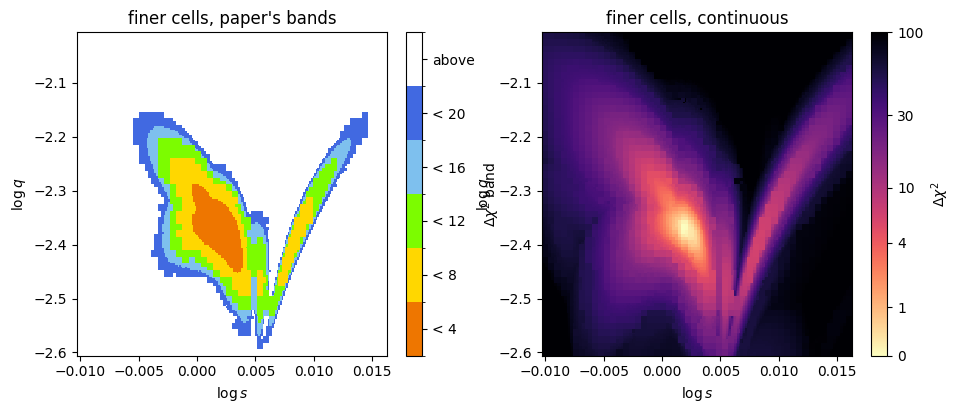

In [7]:
if RECOMPUTE_MAPS:
    moa_cells = lenscape.refine(r, moa_ext, levels=2, best=stored["MOA-2022-BLG-091"]["extended_best"])
else:
    moa_cells = dict(np.load("data/han2025_moa091_cells.npz"))
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
figures.plot_map(moa_cells, bands=H.BANDS, ax=ax[0]); ax[0].set_title("finer cells, paper's bands")
figures.plot_map(moa_cells, ax=ax[1]); ax[1].set_title("finer cells, continuous");

lenscape's map has the same shape as the published one — the V-shaped valley with its minimum at log s ≈ 0.002,
log q ≈ −2.37, the narrow wide-side arm and the gap at log s ≈ 0.006–0.008 — and the solutions lie on the same
tracks in α. Its outer bands are steeper, as expected from the longer baseline it was computed with.

## Figure 3 — model curves of the four solutions

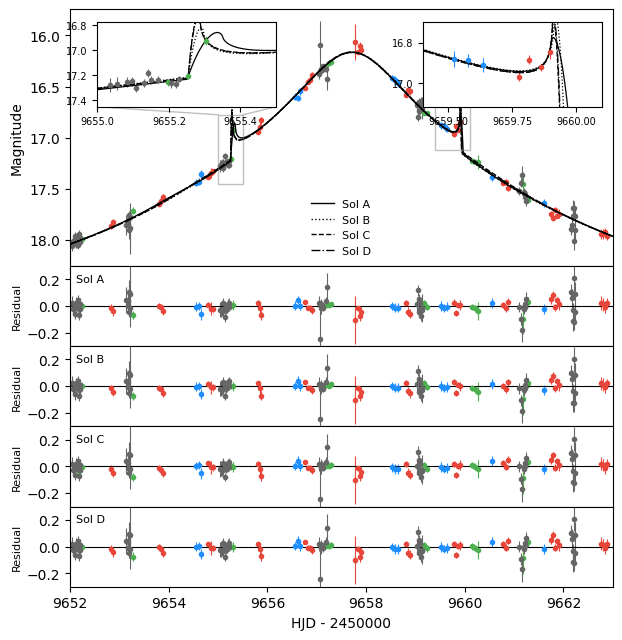

In [8]:
figures.plot_lightcurve(backend, [moa[k] for k in "ABCD"], moa_plotted, labels=[f"Sol {k}" for k in "ABCD"],
                        window=(9652, 9663), insets=[(9655.0, 9655.5), (9659.4, 9660.1)],
                        ref=moa_plotted.names.index("KMTC22"), colors=H.COLORS);

## Figure 4 — lens configurations of MOA-2022-BLG-091

The paper draws the configuration mirrored about the binary axis (`mirror=True`); the light curve is the same.

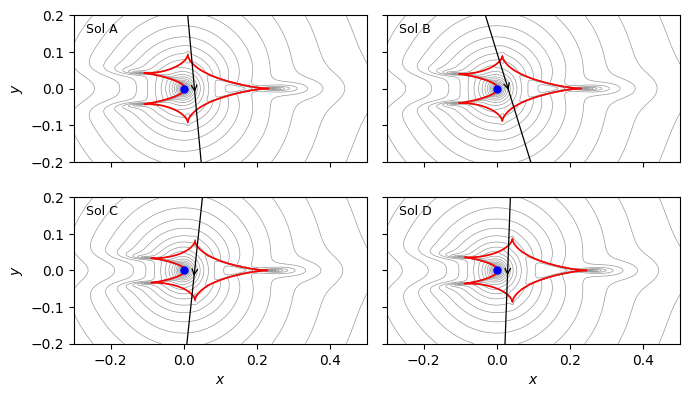

In [9]:
figures.plot_geometry([moa[k] for k in "ABCD"], labels=[f"Sol {k}" for k in "ABCD"],
                      extent=(-0.3, 0.5, -0.2, 0.2), mirror=True);

## Figure 5 — light curve of KMT-2024-BLG-1209

With the outer binary-lens solution and, for comparison, the best single-lens (1L1S) model.

chi2: 2L1S outer 580.6, 1L1S 1418.6


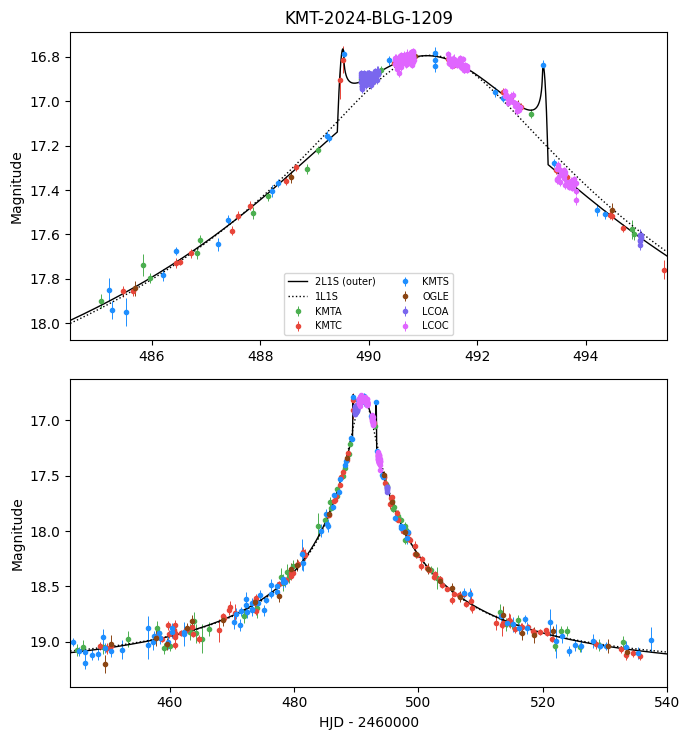

In [10]:
from lenscape.optimize import minimize
from lenscape import single
def chi2_1l1s(x, d=kb_plotted):
    A = single.lc_1l1s(x[0], x[1], abs(x[2]), 10 ** x[3], d.t, 0.0)
    fs, fb = lenscape.model.fluxes(A, d)
    return float((((d.f - fs[d.idx] * A - fb[d.idx]) / d.e) ** 2).sum())
r = minimize(chi2_1l1s, [491.1, 0.03, 70.0, -3.0], method="Nelder-Mead", options=dict(maxfev=4000, adaptive=True))
x1 = r.x
ref = kb_plotted.names.index("KMTC")
A_1l1s = lambda t: single.lc_1l1s(x1[0], x1[1], abs(x1[2]), 10 ** x1[3], t, 0.0)
fs1, fb1 = lenscape.model.fluxes(A_1l1s(kb_plotted.t), kb_plotted)
one = lambda t: 22 - 2.5 * np.log10(fs1[ref] * A_1l1s(t) + fb1[ref])     # on the reference set's (KMTC) scale
print(f"chi2: 2L1S outer {lenscape.model.chi2(backend, kb['Outer'], kb_plotted):.1f}, 1L1S {r.fun:.1f}")
H.plot_two_panels(backend, [("2L1S (outer)", "-", kb["Outer"]), ("1L1S", ":", one)], kb_plotted,
                  zoom=(484.5, 495.5), overall=(444, 540), ref=ref, title="KMT-2024-BLG-1209");

## Figure 6 — Δχ² maps of KMT-2024-BLG-1209

lenscape's map covers the paper's lattice (step 0.00224 in log s, 0.0306 in log q) over the region where the
paper shows coloured cells, plus two cells on each side.

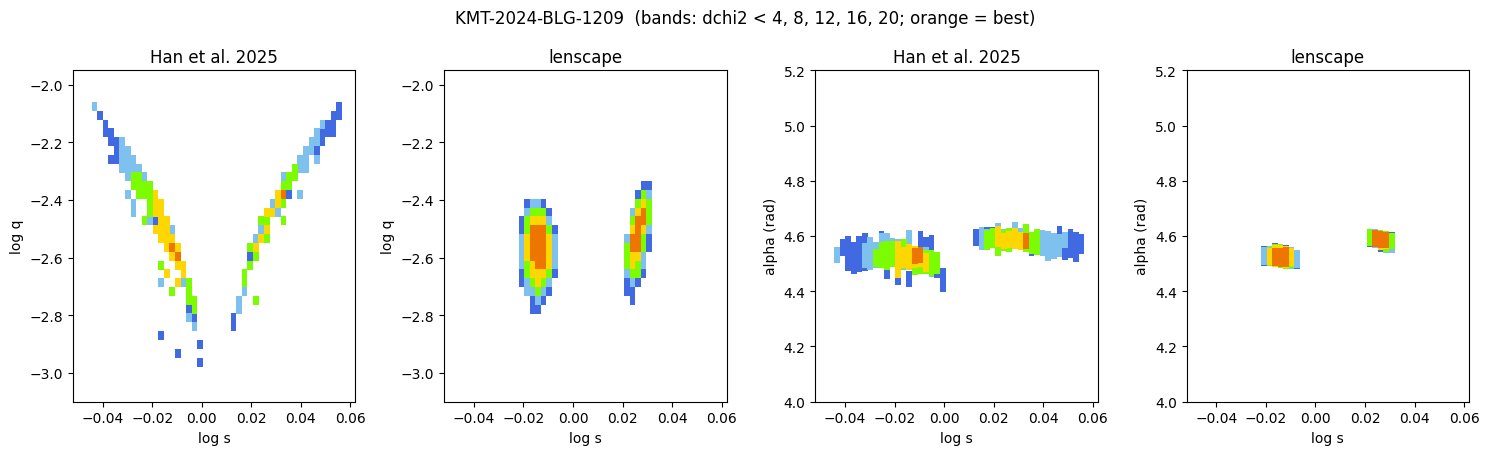

In [11]:
dls, dlq = 0.0022437, 0.030622
if RECOMPUTE_MAPS:
    logs = (-0.04327 + dls * np.arange(-2, 47))[::step]
    logq = (-2.96225 + dlq * np.arange(-2, 32))[::step]
    r = lenscape.lattice(kb_ext, logs, logq, best=stored["KMT-2024-BLG-1209"]["extended_best"])
    best_u0 = r["pars"][np.unravel_index(np.nanargmin(r["chi2"]), r["chi2"].shape)][1]
    kb_map = dict(r, alpha=np.mod(r["pars"][..., 3] + np.where(np.sign(r["pars"][..., 1]) != np.sign(best_u0), np.pi, 0), 2 * np.pi))
else:
    kb_map = dict(np.load("data/han2025_kb1209_lattice.npz"))
left = H.paper_map(src, "f6.eps", (255, 1131, 292, 1605), lenscape.eps.calibrate(679, 0, 1032, 0.05),
                   lenscape.eps.calibrate(744, -3, 1197, -2))
right = H.paper_map(src, "f6.eps", (1349, 2225, 292, 1605), lenscape.eps.calibrate(1751, 0, 1895.8, 0.02),
                    lenscape.eps.calibrate(423, 2, 685.5, 3))
H.compare_maps(left, right, kb_map, (dls * step, dlq * step), 0.057, (-0.052, 0.062), (-3.1, -1.95), (4.0, 5.2),
               "KMT-2024-BLG-1209");

Both maps show the same two degenerate solutions (inner and outer) and the same V-shaped topology, with the minima
at the published (s, q). lenscape's valleys are shorter and broader than the paper's long, narrow arms: along the
paper's arms, lenscape's Δχ² is 2–3 times larger in the outer bands (as for MOA-2022-BLG-091), so they fall
outside Δχ² < 20. The map itself is smooth (below); the difference comes from the data: we have the 580 plotted
points and the public KMTNet baseline, but not the paper's OGLE and LCO data outside the plotted window.

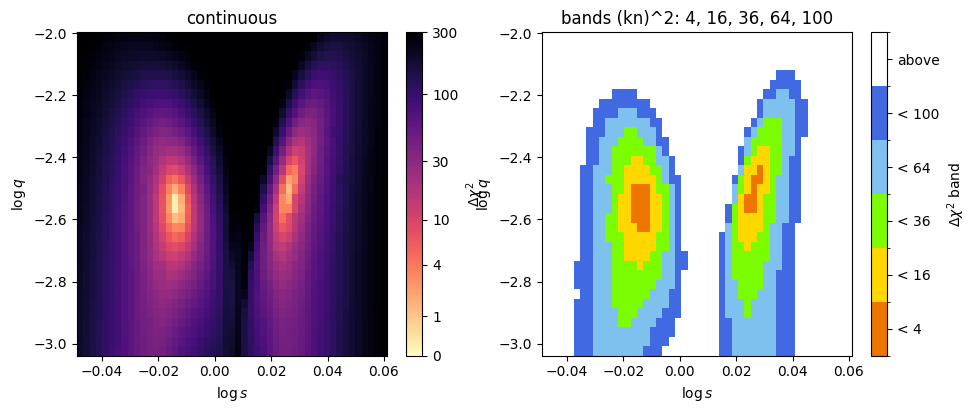

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
figures.plot_map(kb_map, ax=ax[0], vmax=300); ax[0].set_title("continuous")
figures.plot_map(kb_map, bands=(4, 16, 36, 64, 100), ax=ax[1]); ax[1].set_title("bands (kn)^2: 4, 16, 36, 64, 100");

## Figure 7 — lens configurations of KMT-2024-BLG-1209

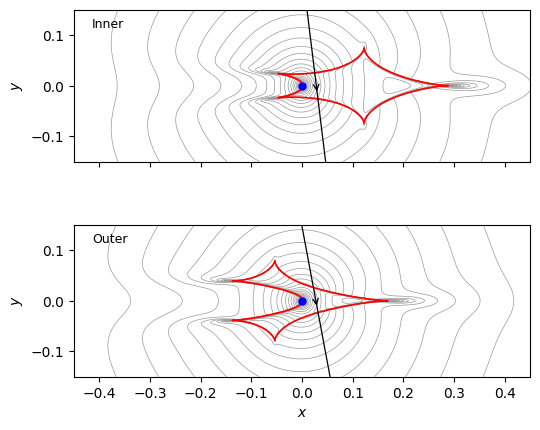

In [13]:
figures.plot_geometry([kb["Inner"], kb["Outer"]], labels=["Inner", "Outer"], ncols=1,
                      extent=(-0.45, 0.45, -0.15, 0.15), mirror=True, figsize=(5.5, 5));